In [1]:
import pandas as pd

# 1. 파일 로드 (이전 군집화 결과 파일과 BASE 파일)
cluster_data = pd.read_csv('KMeans_All_Subclustered2.csv')
base_data = pd.read_csv('KNHANES_2022_2024_ANALYSIS_BASE.csv')

# 2. 공통 키(ID)를 기준으로 데이터 병합 (Inner Join)
merged_data = pd.merge(cluster_data[['ID', 'Sub_Cluster']], base_data, on='ID', how='inner')

# 3. 주요 인구통계 및 기저질환 변수 지정
demo_vars = ['설명_age', '설명_HE_BMI'] # 나이, 체질량지수

# 4. 군집별 평균 및 비율 집계 함수
cont_summary = merged_data.groupby('Sub_Cluster')[demo_vars].mean().round(1)

def get_prop(col, target_val):
    return (merged_data[merged_data[col] == target_val].groupby('Sub_Cluster').size() / merged_data.groupby('Sub_Cluster').size() * 100).round(1)

prop_summary = pd.DataFrame({
    '남성_비율(%)': get_prop('설명_sex', 1), # 1: 남성
    '고혈압_진단율(%)': get_prop('주의_DI1_dg', 1), # 1: 진단
    '당뇨_진단율(%)': get_prop('주의_DE1_dg', 1)  # 1: 진단
})

# 5. 결과 테이블 출력 및 저장
summary_table = pd.concat([cont_summary, prop_summary], axis=1)
summary_table.columns = ['평균_연령', '평균_BMI', '남성_비율(%)', '고혈압_진단율(%)', '당뇨_진단율(%)']
print(summary_table)

merged_data.to_csv('Merged_Cluster_Base.csv', index=False)

             평균_연령  평균_BMI  남성_비율(%)  고혈압_진단율(%)  당뇨_진단율(%)
Sub_Cluster                                                
Group_0-0     53.2    24.6      66.0        28.9       15.5
Group_0-1     49.5    24.4      40.8        27.1        9.0
Group_0-2     58.8    24.6      23.1        36.7       13.9
Group_1-0     51.8    23.9      26.3        24.3       10.7
Group_1-1     61.8    23.9      26.3        37.7       17.5
Group_1-2     61.2    23.5      69.7        36.0       20.2
Group_2-0     50.6    24.4      89.6        26.6       12.5
Group_2-1     44.3    25.1      77.3        23.1       10.8
Group_2-2     50.9    25.0      81.9        25.2       16.9
Group_3-0     40.8    24.3      52.5        14.7        5.1
Group_3-1     56.7    23.8      42.5        30.4       12.2
Group_3-2     33.6    26.7      70.2         9.5        4.8


c:\Users\최지연\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\최지연\AppData\Local\Temp\ipykernel_15564\3551586192.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=fi_df, palette='viridis')


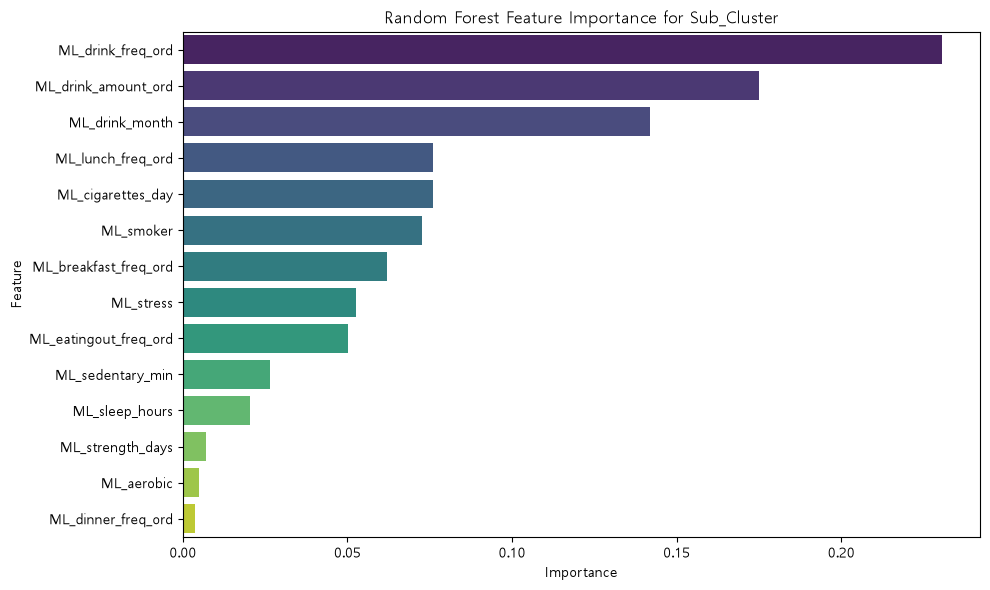

Calculating SHAP values...


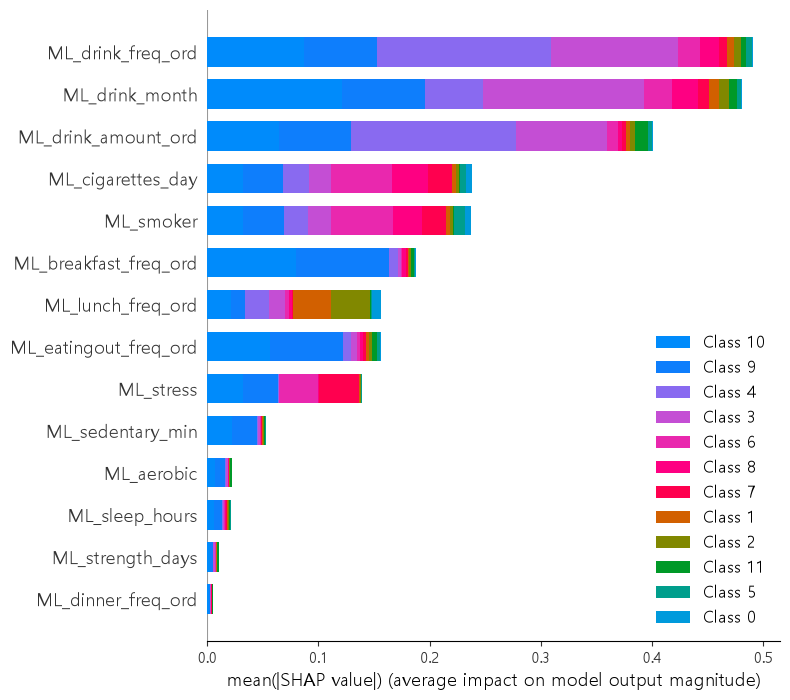

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import shap # pip install shap 필요

# 1. 데이터 준비 (군집 라벨을 Target 변수로 설정)
df = pd.read_csv('KMeans_All_Subclustered2.csv')
features = [col for col in df.columns if col.startswith('ML_')]
X = df[features]
y = df['Sub_Cluster']

# 2. Target 라벨 인코딩 및 모델 학습
le = LabelEncoder()
y_encoded = le.fit_transform(y)

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X, y_encoded)

# 3. 변수 중요도(Feature Importance) 시각화
importances = rf.feature_importances_
fi_df = pd.DataFrame({'Feature': features, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
sns.barplot(x='Importance', y='Feature', data=fi_df, palette='viridis')
plt.title('Random Forest Feature Importance for Sub_Cluster')
plt.tight_layout()
plt.show()

# 4. SHAP Value 기반 심층 해석 (군집별 변수 기여도 파악)
print("Calculating SHAP values...")
X_sample = shap.sample(X, 1000) # 연산 속도를 위해 1000개 샘플링
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_sample)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample, plot_type="bar")